🌟 Exercise 1: Understanding Data Visualization
Task: Explain why data visualization is important in data analysis.
Task: Describe the purpose of a line graph in data visualization.

Why Data Visualization Matters: It turns complex raw numbers into clear visuals, making patterns, trends, and outliers easy to spot at a glance.
Business Impact: Visuals help non-technical stakeholders quickly understand insights and make faster, data-driven decisions.
Purpose of a Line Graph: It connects data points over sequential intervals to show how a continuous value changes over time.
Awesome Strength: The slope of the line reveals the speed of growth or decline and lets you compare multiple trends side by side.

🌟 Exercise 2: Creating a Line Plot for Temperature Variation
Objective: Create a simple line plot using Matplotlib that represents temperature variations over a week.
Tasks:
Use a list of temperature values for each day of the week (e.g., [72, 74, 76, 80, 82, 78, 75]).
Label the x-axis as “Day” and the y-axis as “Temperature (°F)”.
Add a title to the plot.
Display the plot.

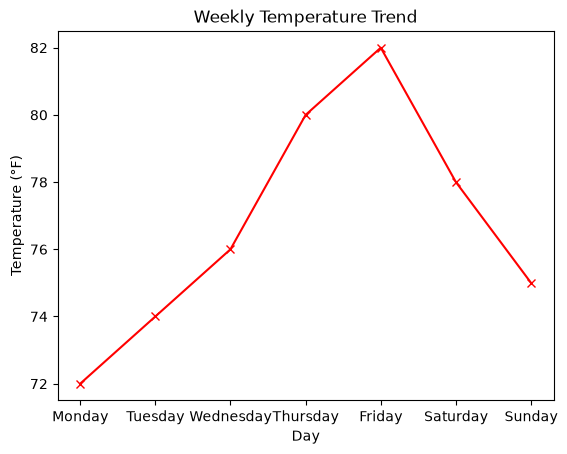

In [21]:
import matplotlib.pyplot as plt

weekly_temps = {
    "Monday": 72,
    "Tuesday": 74,
    "Wednesday": 76,
    "Thursday": 80,
    "Friday": 82,
    "Saturday": 78,
    "Sunday": 75
}

plt.plot(weekly_temps.keys(), weekly_temps.values(), marker="x", color="red")
plt.xlabel("Day")
plt.ylabel("Temperature (°F)")
plt.title("Weekly Temperature Trend")
plt.show()



🌟 Exercise 3: Visualizing Monthly Sales with a Bar Chart
Objective: Generate a bar chart using Matplotlib to visualize monthly sales data for a retail store.
Tasks:
Create a list of sales values for each month (e.g., [5000, 5500, 6200, 7000, 7500]).
Label the x-axis as “Month” and the y-axis as “Sales Amount ($)”.
Add a title to the bar chart.
Display the plot.

In [ ]:
monthly_sales = {
    "January": 5000,
    "February": 5500,
    "March": 6200,
    "April": 7000,
    "May": 7500
}

plt.bar(monthly_sales.keys(), monthly_sales.values(), color="red")
plt.xlabel("Month")
plt.ylabel("Sales Amount ($)")
plt.title("Monthly Sales Performance")
plt.show()


For exercises 4,5,6, you need to download this dataset:
Student Mental health

🌟 Exercise 4: Visualizing the Distribution of CGPA
Objective: Create a histogram to visualize the distribution of students’ CGPA.
Dataset Overview: Assume the CGPA data is categorized into ranges and loaded in a DataFrame named df.
Tasks:
Import necessary libraries.
Use Seaborn’s histplot to create a histogram of the CGPA categories.
Customize the histogram with a specific color and add a title.
Display the plot.



In [ ]:
import seaborn as sns
import pandas as pd

df = pd.read_csv("Student Mental health.csv")

df["What is your CGPA?"] = df["What is your CGPA?"].str.strip()

# # # 3. Define the logical order from lowest CGPA range to highest
# # cgpa_order = ["0 - 1.99", "2.00 - 2.49", "2.50 - 2.99", "3.00 - 3.49", "3.50 - 4.00"]
# # df["What is your CGPA?"] = pd.Categorical(
# #     df["What is your CGPA?"], categories=cgpa_order, ordered=True
# )

df_sorted = df.sort_values("What is your CGPA?")
plt.gca().invert_xaxis()

sns.histplot(data=df, x="What is your CGPA?", color="seagreen", shrink=0.5)


plt.xlabel("CGPA Range")
plt.ylabel("Number of Students")
plt.title("Distribution of Students' CGPA")
plt.xticks(rotation=1)

plt.show()

🌟 Exercise 5: Comparing Anxiety Levels Across Different Genders
Objective: Use a bar plot to compare the proportion of students experiencing anxiety across different genders.
Dataset Overview: The dataset includes columns: ‘Do you have Anxiety?’ and ‘Choose your gender’.
Tasks:
Import necessary libraries.
Use Seaborn to create a bar plot comparing anxiety levels across genders from the dataset df.
Customize the plot with an appropriate color palette and add a title.
Display the plot.

  Choose your gender  Yes_Sum  Total_Students  Proportion
0             Female       24              75    0.320000
1               Male       10              26    0.384615


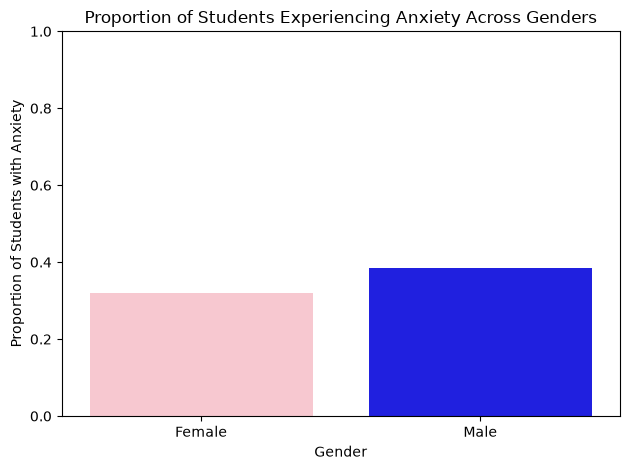

In [ ]:
df["Choose your gender"] = df["Choose your gender"].str.strip()
df["Do you have Anxiety?"] = df["Do you have Anxiety?"].str.strip()

#Grouping by Gender and answer to question
summary = (
    df.groupby("Choose your gender")["Do you have Anxiety?"]
    .agg(
        Yes_Sum=lambda x: (x == "Yes").sum(),
        Total_Students="count"
    )
    .reset_index()
)

# Calculate the proportion (Yes_Sum divided by Total_Students)
summary["Proportion"] = summary["Yes_Sum"] / summary["Total_Students"]

print(summary)

sns.barplot(
    data=summary,
    x="Choose your gender",
    y="Proportion",
    hue="Choose your gender",
    palette={"Female": "pink", "Male": "blue"},

)

plt.xlabel("Gender")
plt.ylabel("Proportion of Students with Anxiety")
plt.title("Proportion of Students Experiencing Anxiety Across Genders")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


🌟 Exercise 6: Exploring the Relationship Between Age and Panic Attacks
Objective: Create a scatter plot to explore the relationship between students’ age and the occurrence of panic attacks.
Dataset Overview: The dataset includes columns: ‘Age’ and ‘Do you have Panic Attacks?’.
Tasks:
Import necessary libraries.
Convert panic attack responses to numeric values (e.g., Yes=1, No=0).
Use Seaborn’s scatterplot to create a scatter plot with ‘Age’ on the x-axis and numeric panic attack responses on the y-axis.
Customize the plot to improve readability by adding labels, a title, and adjusting point styles.
Display the plot.

In [46]:
plt.figure(figsize=(8, 5))


df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Panic_Numeric"] = df["Do you have Panic attack?"].str.strip().map({"Yes": 1, "No": 0})
clean_df = df.dropna(subset=["Age", "Panic_Numeric"])


age_counts = (
    clean_df.groupby(["Age", "Panic_Numeric"])
    .size()
    .reset_index(name="Student_Count")
)

print(age_counts)

     Age  Panic_Numeric  Student_Count
0   18.0              0             23
1   18.0              1              9
2   19.0              0             12
3   19.0              1              9
4   20.0              0              5
5   20.0              1              1
6   21.0              0              3
7   22.0              0              2
8   23.0              0              8
9   23.0              1              5
10  24.0              0             14
11  24.0              1              9


<Figure size 800x500 with 0 Axes>

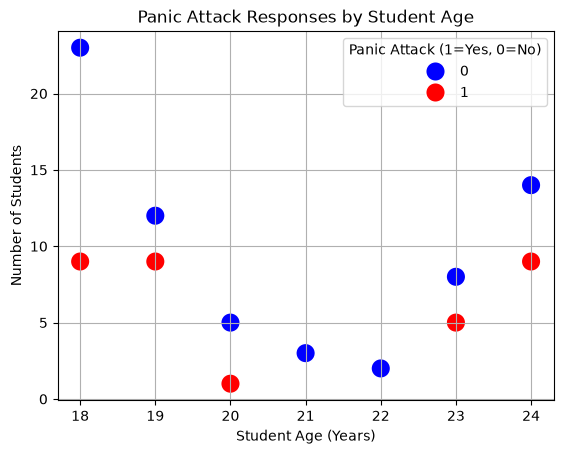

In [50]:
sns.scatterplot(
    data=age_counts,
    x="Age",
    y="Student_Count",
    hue="Panic_Numeric",
    palette={0: "blue", 1: "red"},
    s=200
)

plt.xlabel("Student Age (Years)")
plt.ylabel("Number of Students")
plt.title("Panic Attack Responses by Student Age")
plt.xticks(sorted(age_counts["Age"].unique()))  # Shows exact ages (18, 19, 20...)
plt.legend(title="Panic Attack (1=Yes, 0=No)")
plt.grid(True, linestyle="-", alpha=1)
plt.show()
